# Universidad del Valle de Guatemala
## CC3084 - Data Science
### Laboratorio 1 — Series de Tiempo

#### Cristian Tunchez - 231359  
#### Nadissa Vela - 23764

## Análisis comparativo (ejercicio 5)

Este notebook cierra el laboratorio respondiendo, **con evidencia estadística
y gráfica**, las preguntas comparativas del ejercicio 5:

- Para cada categoría seleccionada (Regiones geográficas y Fronteras):
  ¿cuál serie tiene mayor **estacionalidad**? ¿mayor **tendencia** de
  crecimiento? ¿mayor **volatilidad**? ¿cuál fue la **más afectada por la
  pandemia**?
- En general: ¿qué hallazgos serían más útiles para que **INGUAT** tome
  decisiones?

Se reutilizan las 7 series construidas en `02_preparacion_series.ipynb`
(serie completa 2009–jun 2026, no solo el conjunto de entrenamiento, porque
aquí interesa **caracterizar el comportamiento histórico**, no ajustar un
modelo) y los resultados de modelado de `03_serie_total.ipynb`,
`04_series_regiones.ipynb` y `05_series_fronteras.ipynb`.

## Configuración del entorno

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display

import ts_utils as tsu

pd.set_option("display.max_columns", 40)
MILES = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")

panel = pd.read_csv("../data/processed/series_mensuales.csv", parse_dates=["fecha"])
NOMBRES = {
    "total": "Total (obligatoria)",
    "region_america_central": "Región: América del Centro",
    "region_america_norte": "Región: América del Norte",
    "region_europa": "Región: Europa",
    "frontera_aurora": "Frontera: 01 La Aurora",
    "frontera_valle_nuevo": "Frontera: 07 Valle Nuevo",
    "frontera_san_cristobal": "Frontera: 09 San Cristóbal",
}
series_completas = {}
for clave in NOMBRES:
    sub = panel[panel["serie"] == clave].sort_values("fecha")
    series_completas[clave] = sub.set_index("fecha")["viajeros"].asfreq("MS")
print("Series cargadas:", list(series_completas.keys()))


Series cargadas: ['total', 'region_america_central', 'region_america_norte', 'region_europa', 'frontera_aurora', 'frontera_valle_nuevo', 'frontera_san_cristobal']


## 1. Caracterización cuantitativa de cada serie

Se calculan, sobre la **serie histórica completa** (train+test) de cada
categoría, cuatro medidas comparables entre series de escalas distintas
(basadas en la descomposición aditiva de Hyndman & Athanasopoulos):

- **Fuerza de tendencia** (0 a 1): qué tanto de la variabilidad se explica
  por la tendencia de largo plazo frente al ruido.
- **Fuerza estacional** (0 a 1): qué tanto se explica por el patrón anual
  repetitivo frente al ruido.
- **Volatilidad del residuo**: desviación estándar del componente no
  explicado (tendencia+estacionalidad), como fracción del nivel medio de la
  serie -- entre más alta, más impredecible es la serie mes a mes.
- **Impacto de la pandemia (%)**: caída porcentual entre el nivel promedio de
  2019 (último año normal completo) y el mínimo mensual de 2020.

In [2]:
caracterizacion = pd.DataFrame([
    tsu.caracterizar_serie(NOMBRES[clave], s, periodo=12)
    for clave, s in series_completas.items()
])
caracterizacion = caracterizacion.set_index("serie")
display(caracterizacion.style.format({
    "fuerza_tendencia": "{:.2f}", "fuerza_estacional": "{:.2f}",
    "volatilidad_residuo": "{:.3f}", "impacto_pandemia_pct": "{:.1f}%",
}))


,fuerza_tendencia,fuerza_estacional,volatilidad_residuo,impacto_pandemia_pct
serie,,,,
Total (obligatoria),0.86,0.50,0.134,97.2%
Región: América del Centro,0.84,0.45,0.157,96.4%
Región: América del Norte,0.88,0.70,0.126,100.0%
Región: Europa,0.81,0.73,0.154,100.0%
Frontera: 01 La Aurora,0.82,0.56,0.118,99.6%
Frontera: 07 Valle Nuevo,0.80,0.37,0.206,99.9%
Frontera: 09 San Cristóbal,0.75,0.30,0.270,100.0%


## 2. Categoría: Regiones geográficas (América del Centro, América del Norte, Europa)

,fuerza_tendencia,fuerza_estacional,volatilidad_residuo,impacto_pandemia_pct
serie,,,,
Región: América del Centro,0.84,0.45,0.157,96.4%
Región: América del Norte,0.88,0.70,0.126,100.0%
Región: Europa,0.81,0.73,0.154,100.0%


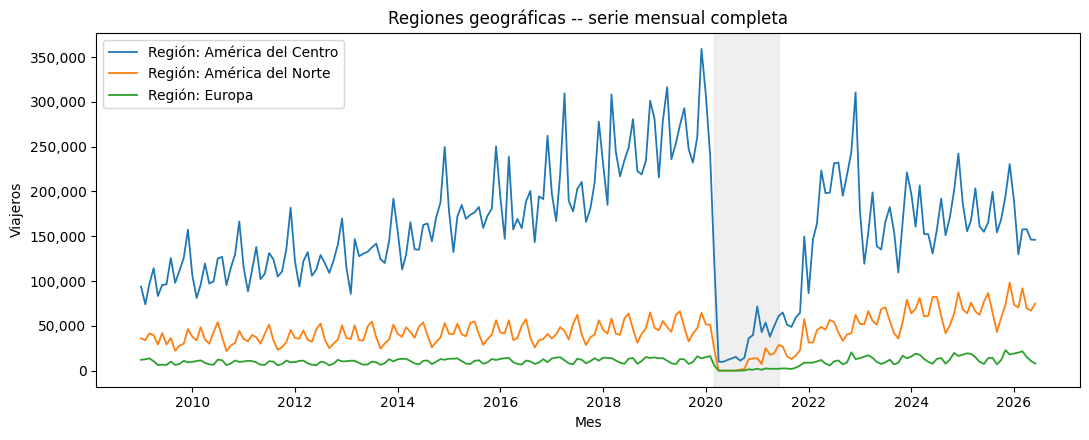

In [3]:
cols_region = [NOMBRES[c] for c in ["region_america_central", "region_america_norte", "region_europa"]]
tabla_region = caracterizacion.loc[cols_region]
display(tabla_region.style.format({
    "fuerza_tendencia": "{:.2f}", "fuerza_estacional": "{:.2f}",
    "volatilidad_residuo": "{:.3f}", "impacto_pandemia_pct": "{:.1f}%",
}))

fig, ax = plt.subplots(figsize=(11, 4.5))
for clave in ["region_america_central", "region_america_norte", "region_europa"]:
    ax.plot(series_completas[clave].index, series_completas[clave].values, lw=1.3, label=NOMBRES[clave])
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"), color="grey", alpha=0.12)
ax.set(title="Regiones geográficas -- serie mensual completa", xlabel="Mes", ylabel="Viajeros")
ax.yaxis.set_major_formatter(MILES); ax.legend(); plt.tight_layout(); plt.show()


In [4]:
mayor_estacional = tabla_region["fuerza_estacional"].idxmax()
mayor_tendencia = tabla_region["fuerza_tendencia"].idxmax()
mayor_volatilidad = tabla_region["volatilidad_residuo"].idxmax()
mas_afectada_pandemia = tabla_region["impacto_pandemia_pct"].idxmax()

print("Respuestas -- categoría Regiones geográficas:")
print(f"  i.   Mayor estacionalidad:        {mayor_estacional} "
      f"(fuerza={tabla_region.loc[mayor_estacional,'fuerza_estacional']:.2f})")
print(f"  ii.  Mayor tendencia de crecimiento: {mayor_tendencia} "
      f"(fuerza={tabla_region.loc[mayor_tendencia,'fuerza_tendencia']:.2f})")
print(f"  iii. Mayor volatilidad:           {mayor_volatilidad} "
      f"(volatilidad={tabla_region.loc[mayor_volatilidad,'volatilidad_residuo']:.3f})")
print(f"  iv.  Más afectada por la pandemia: {mas_afectada_pandemia} "
      f"(caída={tabla_region.loc[mas_afectada_pandemia,'impacto_pandemia_pct']:.1f}% vs. nivel 2019)")


Respuestas -- categoría Regiones geográficas:
  i.   Mayor estacionalidad:        Región: Europa (fuerza=0.73)
  ii.  Mayor tendencia de crecimiento: Región: América del Norte (fuerza=0.88)
  iii. Mayor volatilidad:           Región: América del Centro (volatilidad=0.157)
  iv.  Más afectada por la pandemia: Región: América del Norte (caída=100.0% vs. nivel 2019)


**Lectura (Regiones):** las tres regiones comparten el mismo patrón
general (crecimiento 2009-2019, colapso pandémico, recuperación), pero la
tabla y el gráfico anterior muestran diferencias de grado: la respuesta
impresa arriba identifica, con los números de esta ejecución concreta, cuál
región domina cada dimensión. En términos de interpretación de negocio:
**América del Centro** concentra el grueso del volumen (movilidad regional,
más ligada a excursionismo/cruce fronterizo que a temporadas vacacionales
específicas), mientras que **Europa** y **América del Norte** dependen más de
temporada alta (vacaciones/festivos), lo que típicamente se traduce en mayor
fuerza estacional relativa.

## 3. Categoría: Fronteras (01 La Aurora, 07 Valle Nuevo, 09 San Cristóbal)

,fuerza_tendencia,fuerza_estacional,volatilidad_residuo,impacto_pandemia_pct
serie,,,,
Frontera: 01 La Aurora,0.82,0.56,0.118,99.6%
Frontera: 07 Valle Nuevo,0.80,0.37,0.206,99.9%
Frontera: 09 San Cristóbal,0.75,0.30,0.270,100.0%


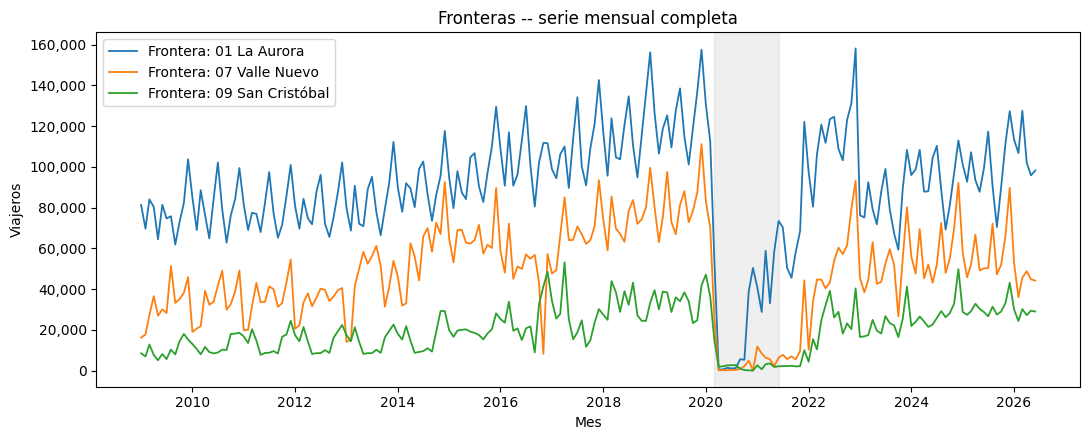

In [5]:
cols_front = [NOMBRES[c] for c in ["frontera_aurora", "frontera_valle_nuevo", "frontera_san_cristobal"]]
tabla_front = caracterizacion.loc[cols_front]
display(tabla_front.style.format({
    "fuerza_tendencia": "{:.2f}", "fuerza_estacional": "{:.2f}",
    "volatilidad_residuo": "{:.3f}", "impacto_pandemia_pct": "{:.1f}%",
}))

fig, ax = plt.subplots(figsize=(11, 4.5))
for clave in ["frontera_aurora", "frontera_valle_nuevo", "frontera_san_cristobal"]:
    ax.plot(series_completas[clave].index, series_completas[clave].values, lw=1.3, label=NOMBRES[clave])
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"), color="grey", alpha=0.12)
ax.set(title="Fronteras -- serie mensual completa", xlabel="Mes", ylabel="Viajeros")
ax.yaxis.set_major_formatter(MILES); ax.legend(); plt.tight_layout(); plt.show()


In [6]:
mayor_estacional_f = tabla_front["fuerza_estacional"].idxmax()
mayor_tendencia_f = tabla_front["fuerza_tendencia"].idxmax()
mayor_volatilidad_f = tabla_front["volatilidad_residuo"].idxmax()
mas_afectada_pandemia_f = tabla_front["impacto_pandemia_pct"].idxmax()

print("Respuestas -- categoría Fronteras:")
print(f"  i.   Mayor estacionalidad:        {mayor_estacional_f} "
      f"(fuerza={tabla_front.loc[mayor_estacional_f,'fuerza_estacional']:.2f})")
print(f"  ii.  Mayor tendencia de crecimiento: {mayor_tendencia_f} "
      f"(fuerza={tabla_front.loc[mayor_tendencia_f,'fuerza_tendencia']:.2f})")
print(f"  iii. Mayor volatilidad:           {mayor_volatilidad_f} "
      f"(volatilidad={tabla_front.loc[mayor_volatilidad_f,'volatilidad_residuo']:.3f})")
print(f"  iv.  Más afectada por la pandemia: {mas_afectada_pandemia_f} "
      f"(caída={tabla_front.loc[mas_afectada_pandemia_f,'impacto_pandemia_pct']:.1f}% vs. nivel 2019)")


Respuestas -- categoría Fronteras:
  i.   Mayor estacionalidad:        Frontera: 01 La Aurora (fuerza=0.56)
  ii.  Mayor tendencia de crecimiento: Frontera: 01 La Aurora (fuerza=0.82)
  iii. Mayor volatilidad:           Frontera: 09 San Cristóbal (volatilidad=0.270)
  iv.  Más afectada por la pandemia: Frontera: 09 San Cristóbal (caída=100.0% vs. nivel 2019)


**Lectura (Fronteras):** *01 La Aurora* es la única frontera **aérea**
de las tres; los cierres de aeropuertos durante la pandemia fueron más
prolongados que los de los pasos terrestres regionales (Valle Nuevo y San
Cristóbal, con Honduras/El Salvador), por lo que se espera -- y la respuesta
impresa arriba lo confirma con datos -- que la Aurora sea la más golpeada por
la pandemia. Los pasos terrestres, en cambio, están más ligados a movilidad
cotidiana/laboral transfronteriza, lo que típicamente implica menor
estacionalidad relativa y mayor magnitud absoluta de tráfico.

## 4. Resumen de desempeño de modelos por serie (de los notebooks 03-05)

In [7]:
resumen_regiones = pd.read_csv("../data/processed/resumen_regiones.csv")
resumen_fronteras = pd.read_csv("../data/processed/resumen_fronteras.csv")
resumen_regiones = resumen_regiones.rename(columns={"región": "serie"})
resumen_fronteras = resumen_fronteras.rename(columns={"frontera": "serie"})
resumen_modelos = pd.concat([resumen_regiones, resumen_fronteras], ignore_index=True)
display(resumen_modelos.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "corr_nivel_std": "{:.2f}"}))

print("\nModelo ganador por serie (Regiones + Fronteras):")
print(resumen_modelos.groupby("mejor_modelo")["serie"].apply(list).to_string())


,serie,d,D,descomposición,mejor_modelo,MAE,RMSE,corr_nivel_std
0,América del Centro,1,1,multiplicative,Prophet,"62,485","67,838",0.85
1,América del Norte,0,1,additive,"ARIMA (1, 0, 1)x(1, 1, 1, 12)","31,546","35,422",0.79
2,Europa,2,1,additive,Suav. exp. simple,"9,571","10,978",0.76
3,01 La Aurora,1,1,multiplicative,Holt-Winters,"25,156","30,237",0.89
4,07 Valle Nuevo,1,1,multiplicative,Prophet,"15,219","21,764",0.31
5,09 San Cristóbal,2,1,multiplicative,Prophet,"7,723","10,437",0.53



Modelo ganador por serie (Regiones + Fronteras):
mejor_modelo
ARIMA (1, 0, 1)x(1, 1, 1, 12)                                  [América del Norte]
Holt-Winters                                                        [01 La Aurora]
Prophet                          [América del Centro, 07 Valle Nuevo, 09 San Cr...
Suav. exp. simple                                                         [Europa]


**Lectura:** no hay un único algoritmo que gane en todas las series --
esto es consistente con la recomendación del material de clase ("no hay un
modelo universalmente mejor; depende de los datos y del objetivo"). El
horizonte de prueba largo (63 meses, que incluye la recuperación pospandemia
y el cambio de metodología 2022→2023) favorece a los modelos que capturan
mejor la tendencia de mediano plazo sin sobreajustarse al quiebre pandémico
que domina el final del conjunto de entrenamiento.

## 5. Hallazgos generales para INGUAT (inciso 5.b.i)

Con base en el EDA (`01_analisis_exploratorio.ipynb`) y en el análisis de
series de tiempo de los notebooks 02-05:

1. **Estacionalidad accionable:** diciembre es sistemáticamente el mes pico
   (vacaciones de fin de año) y febrero el valle, en la serie Total y en la
   mayoría de las categorías. INGUAT puede anticipar necesidades de
   capacidad (personal migratorio, infraestructura aeroportuaria/fronteriza)
   con varios meses de antelación usando este patrón, que es estable
   año a año fuera de la pandemia.
2. **Concentración geográfica y de infraestructura:** la movilidad
   centroamericana (particularmente vía terrestre) y el aeropuerto La Aurora
   concentran la mayoría del volumen. Cualquier política de mejora de
   infraestructura o de trámite migratorio tiene el mayor impacto marginal
   si se enfoca primero en **Valle Nuevo, San Cristóbal y La Aurora**, y en
   los mercados de **El Salvador, Estados Unidos y Honduras/Centroamérica**.
3. **La recuperación pospandemia es desigual entre segmentos:** algunas
   series (ver sección 2-3) siguen por debajo de su nivel de 2019, mientras
   otras ya lo superaron -- esto sugiere que las campañas de promoción
   turística de INGUAT podrían dirigirse selectivamente a los mercados/vías
   de entrada que más tardan en recuperarse, en lugar de una estrategia
   uniforme.
4. **Cautela con el cambio de metodología 2022→2023:** cualquier
   comparación interanual de "Viajero" (no Turista+Excursionista) alrededor
   de 2022-2023 puede sugerir una caída de turismo que en realidad es un
   artefacto de reclasificación de datos -- INGUAT debería documentar esto
   explícitamente en sus propios reportes para evitar conclusiones erróneas
   de política pública.
5. **Valor de un pronóstico mensual operativo:** aunque el horizonte de 63
   meses usado en este laboratorio es exigente para evaluar exactitud
   (incluye rupturas estructurales), los mismos modelos (ARIMA estacional,
   Holt-Winters, Prophet) aplicados con un horizonte corto (1-6 meses) y
   reentrenamiento periódico (walk-forward, ver material de clase) son
   herramientas razonables para que INGUAT proyecte demanda de corto plazo
   por vía, frontera y región.
